<a href="https://colab.research.google.com/github/AliPatrick71/AI-Science-Engineering/blob/main/week4_mathematical_foundations_bitcoin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4 Assignment: Mathematical Foundations of Machine Learning
## AI for Science and Engineering — Bitcoin Price Project

### Project question
Can recent Bitcoin market information help describe or predict the direction of Bitcoin's price over the next 15 minutes?

This notebook succeeds the Week 3 project and imports the same source of data: **BTC-USD 15-minute market data from Yahoo Finance**. It explores numerical variables with descriptive statistics, covariance, correlation, and a scatter plot. It also expresses the input–model–output idea mathematically.



## 1. Import libraries and load the Week 3 dataset

We will use the closing price, opening price, trading volume, and the high price. These are numerical fields in Bitcoin OHLCV market data.

- **Open:** price at the start of the interval
- **High:** highest price during the interval
- **Close:** price at the end of the interval
- **Volume:** amount of Bitcoin traded during the interval



In [1]:
%pip -q install yfinance

In [2]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# Download BTC-USD data at 15-minute intervals, as in Week 3.
data = yf.download(
    "BTC-USD",
    period="60d",
    interval="15m",
    auto_adjust=False,
    progress=False
)

if data.empty:
    raise ValueError(
        "No data was returned. Check your internet connection or download "
        "a Bitcoin OHLCV CSV file and load it with pd.read_csv()."
    )

# Yahoo Finance may return MultiIndex column labels; flatten them if needed.
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

data = data.reset_index()
data.columns = [str(column).lower().replace(" ", "_") for column in data.columns]

required_columns = ["open", "high", "close", "volume"]
missing_columns = [column for column in required_columns if column not in data.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

print("Dataset shape:", data.shape)
print("Available columns:", data.columns.tolist())
display(data.head())

Dataset shape: (5723, 7)
Available columns: ['datetime', 'adj_close', 'close', 'high', 'low', 'open', 'volume']


,datetime,adj_close,close,high,low,open,volume
0,2026-08-29 00:00:00+00:00,77812.492188,77812.492188,77877.851562,77781.007812,77830.000000,113967104
1,2026-08-29 00:15:00+00:00,77901.671875,77901.671875,77953.476562,77808.687500,77812.476562,67407872
2,2026-08-29 00:30:00+00:00,77784.742188,77784.742188,77897.703125,77766.093750,77897.703125,106196992
3,2026-08-29 00:45:00+00:00,77734.492188,77734.492188,77819.000000,77716.648438,77786.289062,913408
4,2026-08-29 01:00:00+00:00,77632.781250,77632.781250,77724.992188,77631.007812,77717.867188,32559104


## 2. Select numerical variables and calculate descriptive statistics

We will calculate the **mean, median, range, variance, and standard deviation** for Open, High, Close, and Volume.

- **Mean:** arithmetic average
- **Median:** middle value after sorting the observations
- **Range:** maximum minus minimum
- **Variance:** measures how spread out values are around the mean, in squared units
- **Standard deviation:** typical spread around the mean, in the original units

These calculations use the sample variance and sample standard deviation provided by pandas (`ddof=1`).

In [3]:
selected_variables = ["open", "high", "close", "volume"]
numeric_data = data[selected_variables].apply(pd.to_numeric, errors="coerce").dropna()

statistics = pd.DataFrame({
    "mean": numeric_data.mean(),
    "median": numeric_data.median(),
    "minimum": numeric_data.min(),
    "maximum": numeric_data.max(),
    "range": numeric_data.max() - numeric_data.min(),
    "variance": numeric_data.var(ddof=1),
    "standard_deviation": numeric_data.std(ddof=1)
})

display(statistics.round(4))

,mean,median,minimum,maximum,range,variance,standard_deviation
open,8.132953e+04,8.150464e+04,75321.8203,8.727904e+04,1.195722e+04,8.175888e+06,2.859351e+03
high,8.142142e+04,8.159206e+04,75505.0000,8.737378e+04,1.186878e+04,8.195056e+06,2.862701e+03
close,8.132992e+04,8.150004e+04,75312.0391,8.727942e+04,1.196738e+04,8.173516e+06,2.858936e+03
volume,1.790556e+08,9.076531e+07,0.0000,4.686840e+09,4.686840e+09,8.838431e+16,2.972950e+08


### Interpreting the descriptive statistics

Use the table above to describe what you observe after running the notebook.

- The mean and median show the typical level of each variable. If they differ noticeably, the distribution may be skewed or affected by unusually large or small observations.
- The range shows the full distance between the smallest and largest observed values.
- Variance and standard deviation describe how much the values vary. A larger standard deviation means observations are more spread out, but the size must be interpreted in the variable's units.
- Bitcoin's price variables are measured in US dollars, while volume is measured in traded units. Their numerical scales should not be compared as if they had the same units.

Since this is time-series market data, the statistics summarize this specific project, they do not guarantee that future values will behave the same way.

## 3. Calculate covariance and correlation

We will compare **Close** and **Volume**.

- **Covariance** indicates whether two variables tend to move together. Its magnitude depends on the variables' units and scales.
- **Pearson correlation** standardizes the relationship to a value between -1 and +1. A value near +1 indicates a strong positive linear association; near -1 indicates a strong negative linear association; and near 0 indicates little linear association.

In [4]:
close_volume = numeric_data[["close", "volume"]]

covariance = close_volume.cov().loc["close", "volume"]
correlation = close_volume.corr(method="pearson").loc["close", "volume"]

print(f"Covariance between Close and Volume: {covariance:,.4f}")
print(f"Pearson correlation between Close and Volume: {correlation:.4f}")

Covariance between Close and Volume: 53,062,126,660.4857
Pearson correlation between Close and Volume: 0.0624


## 4. Plot the relationship between Close and Volume

Each point represents one 15-minute observation. The scatter plot helps us visually inspect whether higher closing prices tend to appear with higher or lower trading volume. Volume can be highly skewed, so a small number of large-volume observations may affect the appearance of the plot.

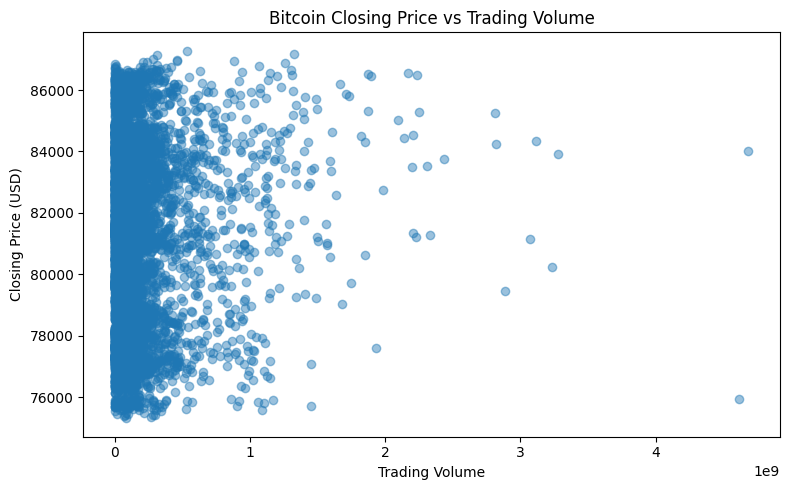

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(numeric_data["volume"], numeric_data["close"], alpha=0.45)
plt.title("Bitcoin Closing Price vs Trading Volume")
plt.xlabel("Trading Volume")
plt.ylabel("Closing Price (USD)")
plt.tight_layout()
plt.show()

### Interpretation: correlation and causation

After running the calculations and viewing the plot, describe the observed correlation using the value printed above and the shape of the scatter plot. State whether the association appears positive, negative, or weak.

**Correlation does not necessarily mean causation.** Even if Close and Volume are correlated, this does not prove that changes in trading volume cause changes in price (or vice versa). Both may be influenced by other factors, and the observations are recorded over time. Correlation describes an association, not a cause-and-effect conclusion.

## 5. Inputs, model, and outputs

For the project, choose **Close** as a simple input variable, \(x\), and the next 15-minute closing price as the output, \(y\).

The Week 3 project created a target for whether the next close is higher than the current close. The expression below shows a simplified regression-style idea for predicting the next closing price:

\[
\text{Input } x_t = \text{Close}_t
\quad\longrightarrow\quad
\text{Model } f_\theta(x_t)
\quad\longrightarrow\quad
\text{Prediction } \hat{y}_{t+1}
\]

A simple linear example is:

\[
\hat{y}_{t+1} = f_\theta(x_t) = wx_t + b
\]

Here, \(w\) and \(b\) are model parameters learned from training data, and \hat{y} is the predicted next-period closing price. The actual next close is \(y_{t+1}\). Prediction error can be represented as \(y_{t+1} - \hat{y}_{t+1}\). A loss function summarizes prediction errors, and model fitting involves choosing parameters that reduce that loss on training data.

This equation is an illustration of the input–model–output concept; this notebook does not train a predictive model or establish that Close alone can reliably predict future prices.

## 6. Conclusion

This notebook represents a small Bitcoin market dataset using numerical columns, summarizes four variables with descriptive statistics, calculates covariance and correlation for Close and Volume, and visualizes their relationship.

